# 06 · Model Selection

**Artemis-X - AI perception for lunar rock and obstacle detection**

**Objective.** Show how the deployed checkpoint (epoch 111) and its operating point (confidence 0.20) were selected using the validation split only, and why (Task F). **No new selection is made here.**

**Research questions**

1. How do the 22 saved checkpoints compare under a fair, ignore-aware metric?
2. Which confidence threshold balances recall and false alarms?
3. How well are large obstacles detected?

**Inputs (published, pixel-free artifacts)**

- `artifacts/evaluation/ignore_aware_val_22_checkpoints.json`
- `artifacts/evaluation/selection_analysis.json`
- `artifacts/provenance/FROZEN_MODEL_CONFIG.json`

> **Provisional results.** All labels were produced by an automated pipeline (S2-H policy) and have **not** been verified by humans. Metrics are measured on synthetic renders only and do not establish performance on real lunar imagery or readiness for rover deployment.

## Setup
The notebook imports the `artemis_x` package from `src/` and reads only published artifacts. It never trains a model, rebuilds a dataset or evaluates the held-out test split.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "artemis_x").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from artemis_x.config import paths
from artemis_x.reporting import artifacts as A, plots as P
P.use_style()
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 90)
# Dataset pixels are never committed (redistribution licence unconfirmed). Set ARTEMIS_SHOW_LOCAL_IMAGES=1 to view
# local images when the dataset folder is present.
SHOW_LOCAL_IMAGES = os.environ.get("ARTEMIS_SHOW_LOCAL_IMAGES") == "1" and paths.local_dataset_available()
FIG = paths.ARTIFACTS / "figures"
print("artemis_x ready | local dataset present:", paths.local_dataset_available(), "| showing local images:", SHOW_LOCAL_IMAGES)

artemis_x ready | local dataset present: True | showing local images: False


## 1. Ignore-aware evaluation
Standard COCO/Ultralytics evaluation counts a detection on an uncertain (REVIEW) rock as a false positive. That penalises the model for
finding real rocks that the automated labels did not confirm. The Artemis-X protocol (Task D.2, `artemis_x.evaluation.ignore_aware`)
follows COCO *crowd* semantics:

- a prediction matching a VALID box with IoU >= 0.5 (greedy by confidence) is a **TP**;
- an unmatched prediction with $\mathrm{IoU} \ge 0.5$ or $\mathrm{IoA} = \frac{|p \cap r|}{|p|} \ge 0.5$ against any REVIEW region $r$ is **ignored**;
- every other prediction is an **FP**, and every unmatched VALID box is an **FN**;
- AP uses 101-point interpolation. AP50-95 averages IoU thresholds 0.50:0.95:0.05. Predictions under 50 px$^2$ are removed.

Three policies are always reported **separately**:
- **primary:** REVIEW regions ignored (approved);
- **secondary:** also ignores the *proposed* sub-threshold regions (not approved);
- **no ignores:** for reference.

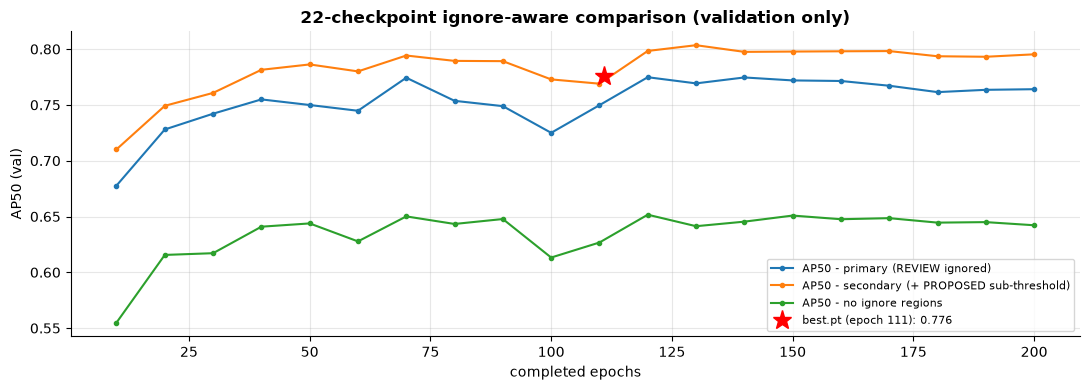

,checkpoint,epoch,AP50 primary,AP50-95 primary,P@0.25,R@0.25,AP50 secondary,AP50 no-ignores
0,epoch_completed_010.pt,10,0.678,0.328,0.733,0.610,0.710,0.555
1,epoch_completed_020.pt,20,0.728,0.379,0.738,0.673,0.749,0.616
2,epoch_completed_030.pt,30,0.742,0.395,0.781,0.656,0.761,0.617
3,epoch_completed_040.pt,40,0.755,0.403,0.740,0.711,0.781,0.641
4,epoch_completed_050.pt,50,0.750,0.405,0.707,0.728,0.786,0.644
5,epoch_completed_060.pt,60,0.745,0.405,0.669,0.742,0.780,0.628
6,epoch_completed_070.pt,70,0.774,0.426,0.781,0.710,0.794,0.650
7,epoch_completed_080.pt,80,0.754,0.412,0.680,0.754,0.789,0.643
8,epoch_completed_090.pt,90,0.749,0.408,0.673,0.751,0.789,0.648
9,epoch_completed_100.pt,100,0.725,0.396,0.600,0.763,0.773,0.613


In [2]:
cmp = A.checkpoint_comparison()
P.checkpoint_curve(cmp)
cmp

All three policies tell the same story: performance rises quickly until about epoch 40 and then **plateaus**. The gap of
about 0.12 AP50 between the primary policy and the no-ignore policy comes from the **evaluation policy, not from the model**.

## 2. Selection rules (fixed in code before any threshold metric was computed)

In [3]:
pd.Series(A.selection_rules()).to_frame("rule")

,rule
checkpoint,"Keep best.pt (provisional primary, user decision) unless a comparison candidate exceed..."
threshold,Recall-oriented: the LOWEST threshold in the grid whose F1 is within 0.02 of the best ...
nms,"Unchanged from the evaluation that produced the candidates: NMS IoU 0.6, max_det 300, ..."
evaluation_policy,"Primary = REVIEW regions ignored (eval_ignore_regions.json), IoU 0.5, IoA 0.5, 101-pt ..."


In [4]:
A.candidate_summary(0.20)

,checkpoint,AP50,AP50-95,precision,recall,F1,FP/image,large recall,very-large recall
0,best.pt,0.776,0.431,0.696,0.775,0.734,9.47,0.807,0.760
1,epoch_completed_120.pt,0.775,0.433,0.715,0.768,0.741,8.54,0.824,0.784
2,epoch_completed_130.pt,0.769,0.429,0.652,0.792,0.715,11.83,0.818,0.784
3,epoch_completed_140.pt,0.775,0.433,0.719,0.766,0.742,8.39,0.812,0.774


No comparison candidate beat `best.pt` (epoch 111) by more than 0.005 AP50, so `best.pt` was kept. **Epoch 120** has the
same AP and about 1.7 points better large-rock recall. It was presented to the project owner, who chose to keep epoch 111.

## 3. Operating point

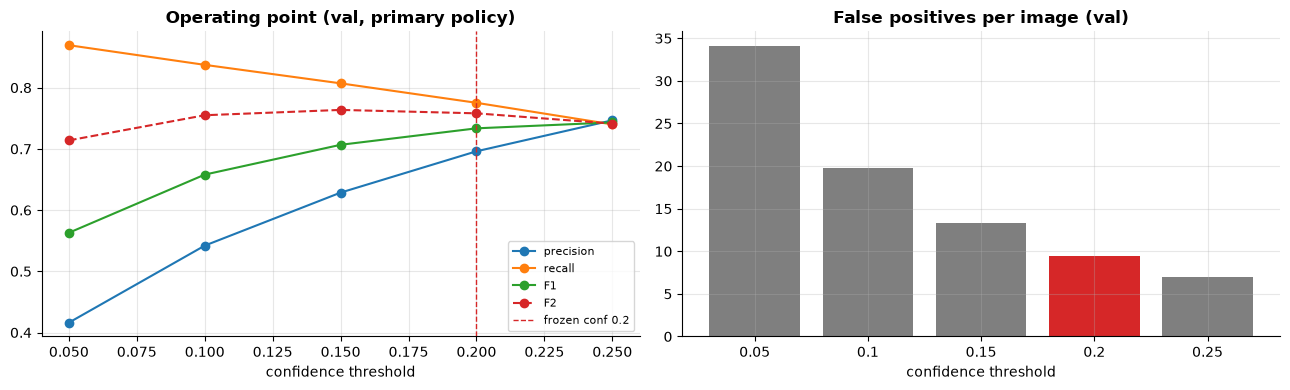

,conf,precision,recall,f1,f2,fp_per_image,tp,fp,fn
0,0.05,0.416,0.869,0.563,0.714,34.11,22450,31486,3372
1,0.10,0.542,0.837,0.658,0.755,19.79,21620,18268,4202
2,0.15,0.629,0.807,0.707,0.764,13.34,20840,12315,4982
3,0.20,0.696,0.775,0.734,0.758,9.47,20021,8742,5801
4,0.25,0.747,0.740,0.743,0.741,7.02,19108,6482,6714


In [5]:
tab = A.threshold_table("best.pt")
P.threshold_tradeoff(tab, 0.20)
tab[["conf", "precision", "recall", "f1", "f2", "fp_per_image", "tp", "fp", "fn"]]

The best F1 on the grid is at 0.25. The **recall-oriented rule** selects the lowest threshold whose F1 is within 0.02 of
that maximum: **0.20**. Compared with 0.25 it finds about 900 more rocks (+3.5 points recall) for about 2.5 more false alarms per image.
For a rover, a missed obstacle costs more than a false alarm.

## 4. Recall by rock size (validation)

In [6]:
sel = A.load_json("evaluation/selection_analysis.json")["candidates"]["best.pt"]["size_recall"]
pd.DataFrame(sel).T[["gt", "recall@0.1", "recall@0.15", "recall@0.2", "recall@0.25", "precision@0.2"]].loc[A.SIZE_ORDER]

,gt,recall@0.1,recall@0.15,recall@0.2,recall@0.25,precision@0.2
small <400,17001.0,0.816,0.779,0.740,0.698,0.641
medium 400-2500,7412.0,0.887,0.869,0.849,0.828,0.818
large 2500-10000,1205.0,0.849,0.829,0.815,0.794,0.871
very large >=10000,204.0,0.784,0.765,0.760,0.745,0.767
large (all) >=2500,1409.0,0.840,0.820,0.807,0.787,0.852


In [7]:
fn = A.load_json("evaluation/selection_analysis.json")["fn_analysis_selected"]
pd.DataFrame(fn["by_size"]).T.assign(total=lambda x: x.sum(axis=1))

,found_below_threshold,localisation_iou_0.1_0.5,near_miss_iou_lt_0.1,total
small <400,2619,977,817,4413
medium 400-2500,725,262,129,1116
large 2500-10000,134,62,27,223
very large >=10000,25,15,9,49


About 60% of misses are rocks the model *did* find below the threshold, about 23% are localisation errors (merged or
split boxes), and about 17% are near-total misses. Visual inspection (local-only) found that many "missed large rocks" are label
artefacts, such as crater rims, slopes and merged boulders.

Genuine failures concentrate in:
- dark, low-illumination scenes;
- dense boulder fields;
- large shadowed boulders against the black sky.

## 5. The frozen configuration

In [8]:
f = A.frozen_config()
pd.concat([pd.Series(f["inference"]).drop("note"), pd.Series({"model sha256": f["model"]["sha256"], "selected on": f["selected_on"],
          "test split used for selection": f["test_split_used"]})]).to_frame("frozen value")

,frozen value
imgsz,736
conf,0.2
nms_iou,0.6
max_det,300
min_box_area_px2,50.0
classes,[0]
agnostic_nms,False
input,"native 720x480 render, RGB"
model sha256,413d0481a728a310f5b919d069676ee5ddd2091e81b4b663831e1e977a0752eb
selected on,validation split only (923 images)


## Provenance
Each artifact below is a verified copy (or path-sanitised derivative) of a historical experiment output; `scripts/verify_artifacts.py` re-checks every hash.

In [9]:
A.provenance(['evaluation/ignore_aware_val_22_checkpoints.json', 'evaluation/selection_analysis.json', 'provenance/FROZEN_MODEL_CONFIG.json'])

,artifact,mode,source (local experiments/),sha256
0,artifacts/evaluation/ignore_aware_val_22_checkpoints.json,COPY,experiments/task-e/full-training-config-a-200-s42/ignore_aware_val.json,86284998e632b1b7...
1,artifacts/evaluation/selection_analysis.json,COPY,experiments/task-f/model-selection-001/selection_analysis.json,012b55386f4a742b...
2,artifacts/provenance/FROZEN_MODEL_CONFIG.json,COPY,experiments/task-f/model-selection-001/FROZEN_MODEL_CONFIG.json,efdc5802cbc3a4f0...


## Conclusion
- Selection used **only the validation split** and pre-declared rules.
- Frozen model: `best.pt`, epoch 111. Operating point: confidence 0.20, NMS IoU 0.60, max 300 detections, boxes under 50 px$^2$
  removed. Evaluation policy: REVIEW regions ignored.
- Validation at that operating point: precision 0.696, recall 0.775, F1 0.734, about 9.5 false positives per image, AP50 0.776.
- Large-obstacle recall (0.807) is lower than medium-rock recall (0.849). That is the most safety-relevant weakness.

**Next:** [07_final_evaluation.ipynb](07_final_evaluation.ipynb)